# Red de memoria asociativa: Recuperación mediante minimización de energía


La energía de la red está dada por:
$$
E(\mathbf{q}) = \frac{1}{2} \sum_{i=1}^N q_i^2 - \frac{1}{\beta} \ln \left( \sum_{\mu=1}^P \exp \left[ \beta \sum_{i=1}^N x_{\mu i} q_i \right] \right)
$$

Calculando el gradiente respecto a $q_i$ e introduciendo la regla de descenso de gradiente $q_i^{(t+1)} = q_i^{(t)} - \alpha \frac{\partial E}{\partial q_i}$, obtenemos:
$$
q_i^{(t+1)} = q_i^{(t)} - \alpha \left( q_i^{(t)} - \sum_{\mu=1}^P w_\mu x_{\mu i} \right)
$$
donde $w_\mu$ es la función *softmax* sobre las proyecciones de los patrones. Para $\alpha = 1$, la regla se simplifica a $q_i^{(t+1)} = \sum_{\mu=1}^P w_\mu x_{\mu i}$, equivalente a un mecanismo de atención sobre los patrones almacenados.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import accuracy_score

# Configuración de precisión y reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)
tf.keras.backend.set_floatx('float64')

def plot_pattern(pattern, title="Patrón"):
    plt.figure(figsize=(4, 4))
    img = plt.imshow(pattern.reshape(8, 8), cmap='coolwarm')
    plt.title(title)
    plt.colorbar(img, fraction=0.046, pad=0.04, label="Estado q")
    plt.axis('off')
    plt.show()

print("Entorno preparado.")

Entorno preparado.


## 1. Definición de los patrones almacenados

Almacenamos las letras 'J' y 'H' como imágenes binarias de $8 \times 8$. Utilizamos $+1$ para píxeles activos y $-1$ para inactivos. Los aplanamos para formar la matriz $X$ de tamaño $P \times N$ (donde $P=2$ patrones y $N=64$ neuronas).

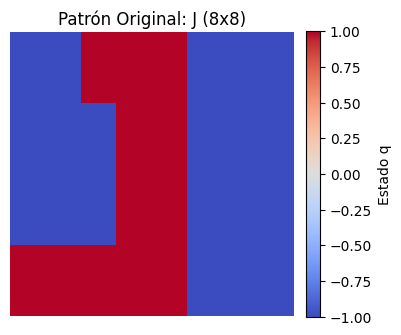

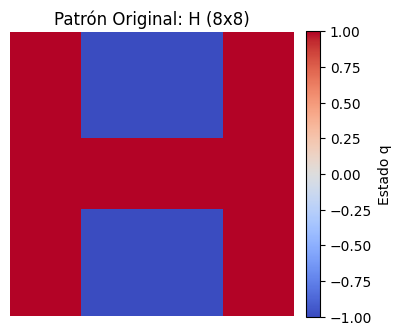

In [14]:
J = np.array([
    [-1, -1,  1,  1,  1, -1, -1, -1],
    [-1, -1,  1,  1,  1, -1, -1, -1],
    [-1, -1, -1,  1,  1, -1, -1, -1],
    [-1, -1, -1,  1,  1, -1, -1, -1],
    [-1, -1, -1,  1,  1, -1, -1, -1],
    [-1, -1, -1,  1,  1, -1, -1, -1],
    [ 1,  1,  1,  1,  1,  -1, -1, -1],
    [ 1,  1,  1,  1,  1,  -1, -1, -1]
])

H = np.array([
    [ 1,  1, -1, -1, -1, -1,  1,  1],
    [ 1,  1, -1, -1, -1, -1,  1,  1],
    [ 1,  1, -1, -1, -1, -1,  1,  1],
    [ 1,  1,  1,  1,  1,  1,  1,  1],
    [ 1,  1,  1,  1,  1,  1,  1,  1],
    [ 1,  1, -1, -1, -1, -1,  1,  1],
    [ 1,  1, -1, -1, -1, -1,  1,  1],
    [ 1,  1, -1, -1, -1, -1,  1,  1]
])

# Aplanamos para obtener vectores de 64 componentes
J_flat = J.flatten()
H_flat = H.flatten()

X = np.vstack([J_flat, H_flat])

plot_pattern(J_flat, "Patrón Original: J (8x8)")
plot_pattern(H_flat, "Patrón Original: H (8x8)")

## 2. Implementación del modelo en Keras

Dado que la regla de actualización es un descenso de gradiente sobre una función de energía escalar, podemos implementar el sistema como un modelo de Keras donde el estado $\mathbf{q}$ actúa como los pesos entrenables del modelo. La función de pérdida será exactamente la energía $E(\mathbf{q})$.

In [15]:
class MemoriaAsociativa(keras.Model):
    def __init__(self, X, beta=10.0):
        super().__init__()
        self.X = tf.constant(X, dtype=tf.float64)
        self.beta = tf.constant(beta, dtype=tf.float64)
        # El estado q son los parámetros a optimizar
        self.q = self.add_weight(
            name="estado_q",
            shape=(X.shape[1],),
            initializer="zeros",
            trainable=True,
            dtype=tf.float64
        )

    def energia(self):
        # Primer término: 0.5 * ||q||^2
        termino1 = 0.5 * tf.reduce_sum(self.q ** 2)
        # Segundo término: -(1/beta) * logsumexp(beta * X q)
        proyecciones = tf.linalg.matvec(self.X, self.q) # X @ q
        termino2 = (1.0 / self.beta) * tf.reduce_logsumexp(self.beta * proyecciones)

        return termino1 - termino2

    def call(self, q_in=None):
        if q_in is not None:
            self.q.assign(q_in)
        return self.q

### 3. Experimentos computacionales (a): Visualización de la recuperación

**Nota importante sobre el color:** Como $\alpha = 1$, la actualización es $q^{(t+1)} = \sum w_\mu x_{\mu i}$. Si usamos un $\beta$ grande (ej. 10), la softmax se vuelve determinista ($w \approx [1, 0]$) y $q$ salta exactamente a los valores binarios $\pm 1$ (rojo y azul puro). Para poder visualizar el estado **continuo** (valores intermedios), usaremos un $\beta$ más pequeño ($\beta = 0.1$) en esta primera prueba, lo que forzará a la red a mezclar los patrones.

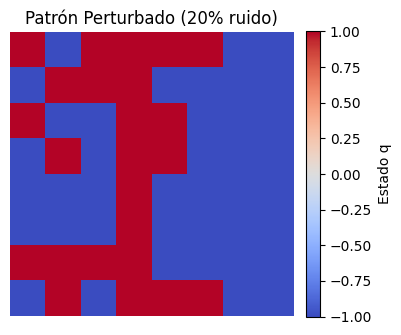

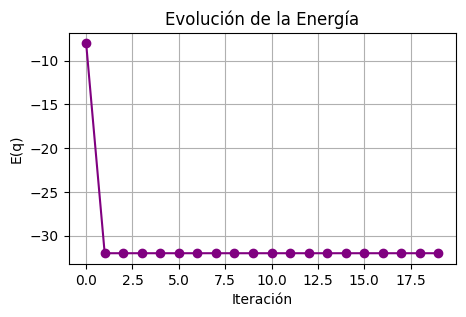

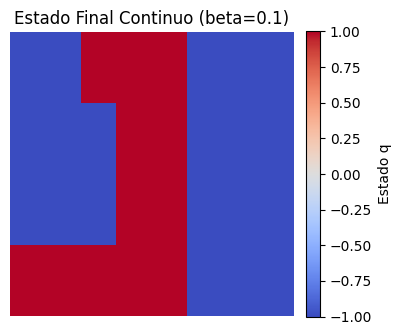

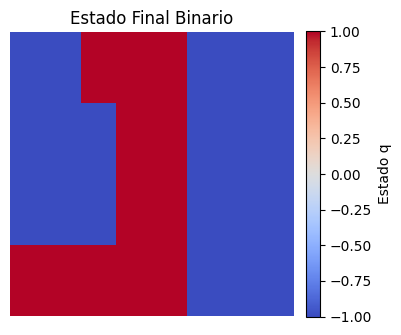

Porcentaje de recuperación (exactitud): 100.00%


In [16]:
def perturbar(patron, porcentaje):
    q_pert = patron.copy()
    N = len(patron)
    num_pert = int(N * porcentaje / 100)
    indices = np.random.choice(N, num_pert, replace=False)
    q_pert[indices] *= -1
    return q_pert

beta_continuo = 0.1
alpha = 1.0
max_iter = 20

# patrón perturbado
q_init = perturbar(J_flat, porcentaje=20)
plot_pattern(q_init, "Patrón Perturbado (20% ruido)")

# Instanciar modelo
modelo = MemoriaAsociativa(X, beta=beta_continuo)
optimizador = keras.optimizers.SGD(learning_rate=alpha)
modelo.call(q_init)

historial_energia = []

# Bucle de descenso de gradiente
for i in range(max_iter):
    with tf.GradientTape() as tape:
        E = modelo.energia()
    grad = tape.gradient(E, modelo.trainable_variables)
    optimizador.apply_gradients(zip(grad, modelo.trainable_variables))
    historial_energia.append(E.numpy())

q_final = modelo.q.numpy()

plt.figure(figsize=(5, 3))
plt.plot(historial_energia, marker='o', color='purple')
plt.title("Evolución de la Energía")
plt.xlabel("Iteración")
plt.ylabel("E(q)")
plt.grid(True)
plt.show()

plot_pattern(q_final, f"Estado Final Continuo (beta={beta_continuo})")

# Binarizamos
q_binario = np.sign(q_final)
plot_pattern(q_binario, "Estado Final Binario")

precision = accuracy_score(J_flat, q_binario) * 100
print(f"Porcentaje de recuperación (exactitud): {precision:.2f}%")

### 4. Experimentos computacionales (b): Estudio del porcentaje de perturbación

Analizamos cómo afecta el nivel de ruido inicial a la capacidad de la red para recuperar el patrón original. Usamos un $\beta = 10$ (alta selectividad) para que la red recupere el patrón puro.

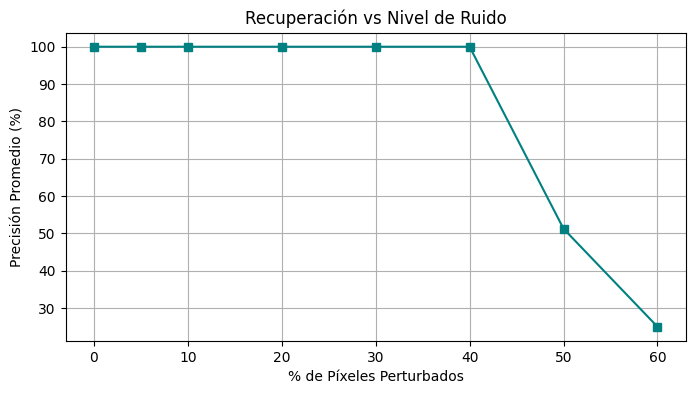

In [17]:
porcentajes_ruido = [0, 5, 10, 20, 30, 40, 50, 60]
repeticiones = 20
precisiones_promedio = []

for pct in porcentajes_ruido:
    precisiones_pct = []
    for _ in range(repeticiones):
        q_init = perturbar(J_flat, porcentaje=pct)
        modelo_temp = MemoriaAsociativa(X, beta=10.0)
        modelo_temp.call(q_init)
        opt_temp = keras.optimizers.SGD(learning_rate=1.0)

        for _ in range(10):
            with tf.GradientTape() as tape:
                E = modelo_temp.energia()
            grad = tape.gradient(E, modelo_temp.trainable_variables)
            opt_temp.apply_gradients(zip(grad, modelo_temp.trainable_variables))

        q_bin = np.sign(modelo_temp.q.numpy())
        precisiones_pct.append(accuracy_score(J_flat, q_bin))

    precisiones_promedio.append(np.mean(precisiones_pct) * 100)

plt.figure(figsize=(8, 4))
plt.plot(porcentajes_ruido, precisiones_promedio, marker='s', linestyle='-', color='teal')
plt.title("Recuperación vs Nivel de Ruido")
plt.xlabel("% de Píxeles Perturbados")
plt.ylabel("Precisión Promedio (%)")
plt.grid(True)
plt.show()

### 5. Experimentos computacionales (c): Influencia del parámetro $\beta$

El parámetro $\beta$ actúa como la inversa de la temperatura. Un $\beta$ pequeño genera un estado continuo (mezcla de patrones), mientras que un $\beta$ grande fuerza la recuperación del patrón binario exacto. Evaluamos la energía y el estado final para distintos valores.

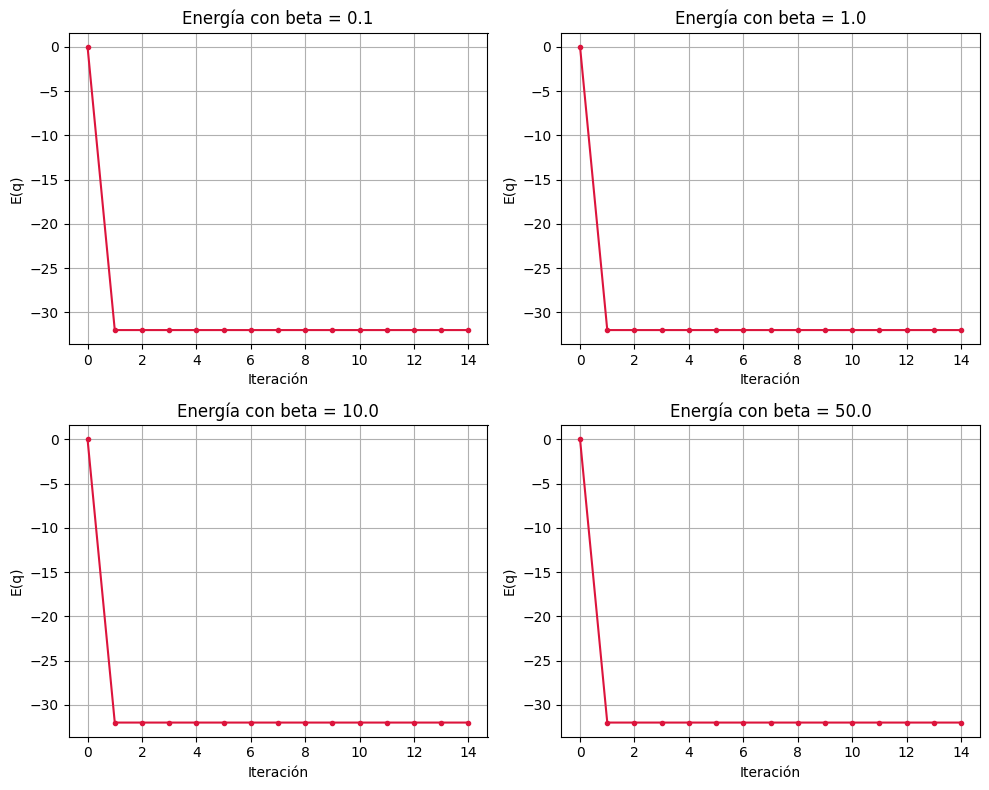

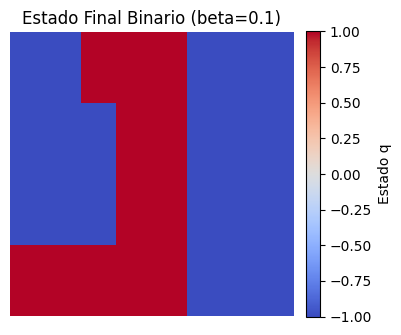

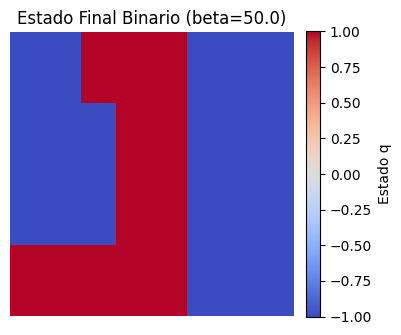

In [18]:
betas = [0.1, 1.0, 10.0, 50.0]
q_init = perturbar(J_flat, porcentaje=25)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, b in enumerate(betas):
    modelo_b = MemoriaAsociativa(X, beta=b)
    modelo_b.call(q_init)
    opt_b = keras.optimizers.SGD(learning_rate=1.0)

    historial_E = []
    for _ in range(15):
        with tf.GradientTape() as tape:
            E = modelo_b.energia()
        grad = tape.gradient(E, modelo_b.trainable_variables)
        opt_b.apply_gradients(zip(grad, modelo_b.trainable_variables))
        historial_E.append(E.numpy())

    axes[i].plot(historial_E, marker='.', color='crimson')
    axes[i].set_title(f"Energía con beta = {b}")
    axes[i].set_xlabel("Iteración")
    axes[i].set_ylabel("E(q)")
    axes[i].grid(True)

plt.tight_layout()
plt.show()

for b in [0.1, 50.0]:
    modelo_b = MemoriaAsociativa(X, beta=b)
    modelo_b.call(q_init)
    opt_b = keras.optimizers.SGD(learning_rate=1.0)
    for _ in range(15):
        with tf.GradientTape() as tape:
            E = modelo_b.energia()
        grad = tape.gradient(E, modelo_b.trainable_variables)
        opt_b.apply_gradients(zip(grad, modelo_b.trainable_variables))

    plot_pattern(np.sign(modelo_b.q.numpy()), f"Estado Final Binario (beta={b})")

### Interpretación de los resultados

1. **Visualización (a)**: Al usar $\beta = 0.1$, la red no está segura de qué patrón elegir y genera un estado continuo con mezcla de colores (valores intermedios). Al aplicar `np.sign`, colapsa a un estado binario. Si se usara $\beta = 10$, el estado final continuo ya se vería binario, porque la red elegiría un patrón concreta y lo copiaría exactamente.
2. **Robustez al ruido (b)**: Con $\beta=10$, la red recupera perfectamente la 'J' para ruidos menores al 40%. Para ruidos mayores, la proyección inicial se acerca más a la 'H', y la red recupera la 'H' (error de memoria asociativa).
3. **Influencia de $\beta$ (c)**:
   - **$\beta$ pequeño (0.1)**: La softmax es casi uniforme. El estado $q$ es un promedio borroso de ambos patrones (se ven muchos tonos intermedios).
   - **$\beta$ grande (10 o 50)**: La softmax se vuelve un `argmax`. La red colapsa inmediatamente al patrón más cercano, mostrando colores puros y recuperando la memoria perfectamente.